In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer


In [2]:
stroke_data = pd.read_csv("/data/healthcare-dataset-stroke-data.xls")

In [3]:
stroke_data.columns = stroke_data.columns.str.lower().str.replace(' ', '_')
stroke_data

,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [4]:
categorical_columns = [
    c for c in stroke_data.columns
    if stroke_data[c].dtype == 'object' or pd.api.types.is_string_dtype(stroke_data[c])
]
numeric_columns = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
feature_columns = categorical_columns + numeric_columns

# EDA


In [5]:
stroke_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [6]:
stroke_data.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [7]:
imputer = SimpleImputer(strategy="median")
stroke_data[["bmi"]] = imputer.fit_transform(stroke_data[["bmi"]])

In [8]:
global_stroke_rate = stroke_data.stroke.mean()
global_stroke_rate

np.float64(0.0487279843444227)

In [9]:
for col in categorical_columns:
    df_group = stroke_data.groupby(col).stroke.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_stroke_rate
    df_group = df_group.sort_values('diff', ascending=False)
    print(col)
    display(df_group)
    print()

gender


,mean,count,diff
gender,,,
Male,0.051064,2115,0.002336
Female,0.047094,2994,-0.001634
Other,0.000000,1,-0.048728



ever_married


,mean,count,diff
ever_married,,,
Yes,0.065613,3353,0.016885
No,0.016505,1757,-0.032223



work_type


,mean,count,diff
work_type,,,
Self-employed,0.079365,819,0.030637
Private,0.050940,2925,0.002212
Govt_job,0.050228,657,0.001500
children,0.002911,687,-0.045817
Never_worked,0.000000,22,-0.048728



residence_type


,mean,count,diff
residence_type,,,
Urban,0.052003,2596,0.003275
Rural,0.045346,2514,-0.003382



smoking_status


,mean,count,diff
smoking_status,,,
formerly smoked,0.079096,885,0.030368
smokes,0.053232,789,0.004504
never smoked,0.047569,1892,-0.001159
Unknown,0.030440,1544,-0.018288


In [10]:
stroke_data[numeric_columns + ['stroke']].corr()['stroke'].sort_values(ascending=False)

stroke               1.000000
age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
bmi                  0.036110
Name: stroke, dtype: float64

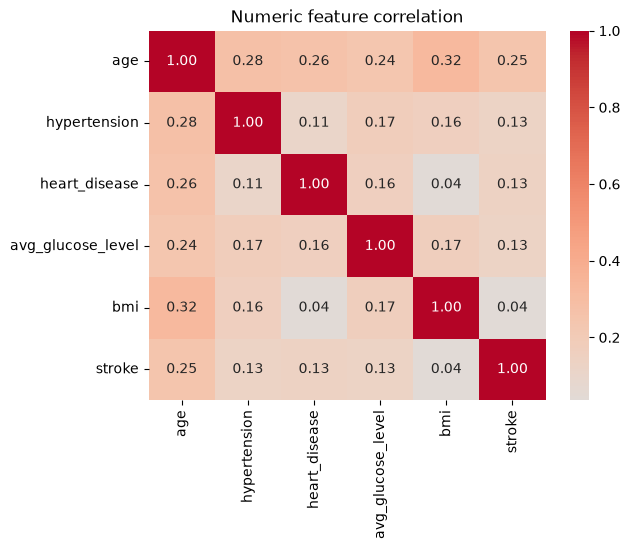

In [11]:
sns.heatmap(
    stroke_data[numeric_columns + ['stroke']].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
)
plt.title('Numeric feature correlation')
plt.show()

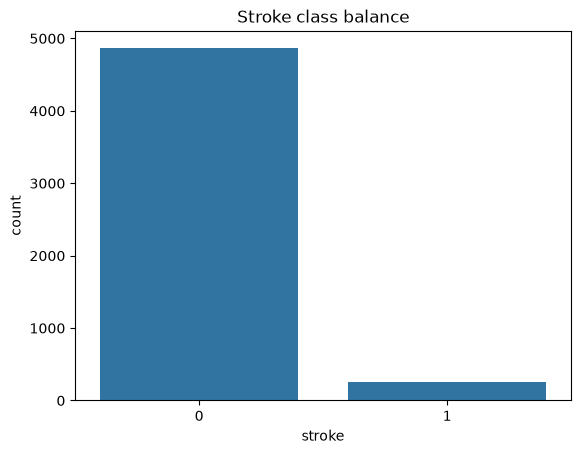

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64

In [12]:
sns.countplot(data=stroke_data, x='stroke')
plt.title('Stroke class balance')
plt.show()

stroke_data.stroke.value_counts(normalize=True)

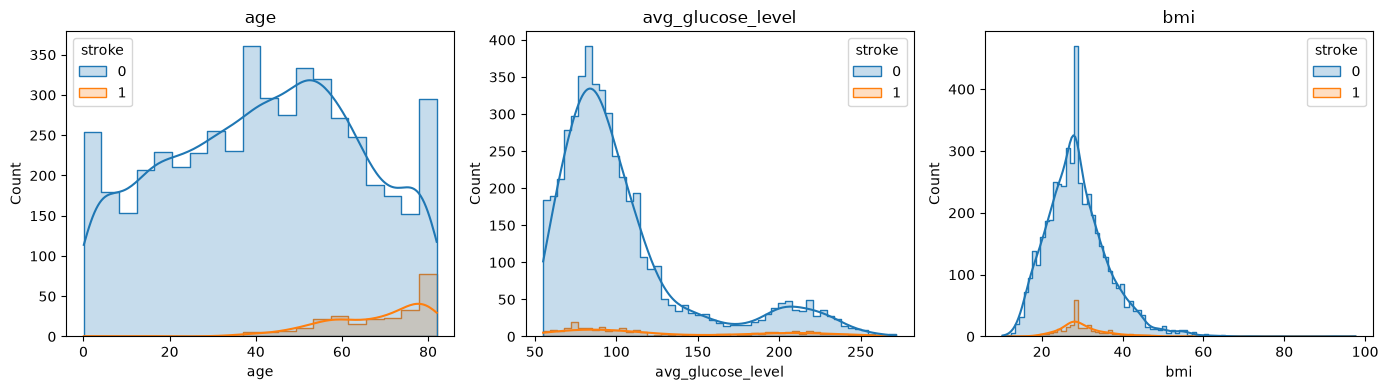

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    sns.histplot(data=stroke_data, x=col, hue='stroke', kde=True, ax=ax, element='step')
    ax.set_title(col)

plt.tight_layout()
plt.show()

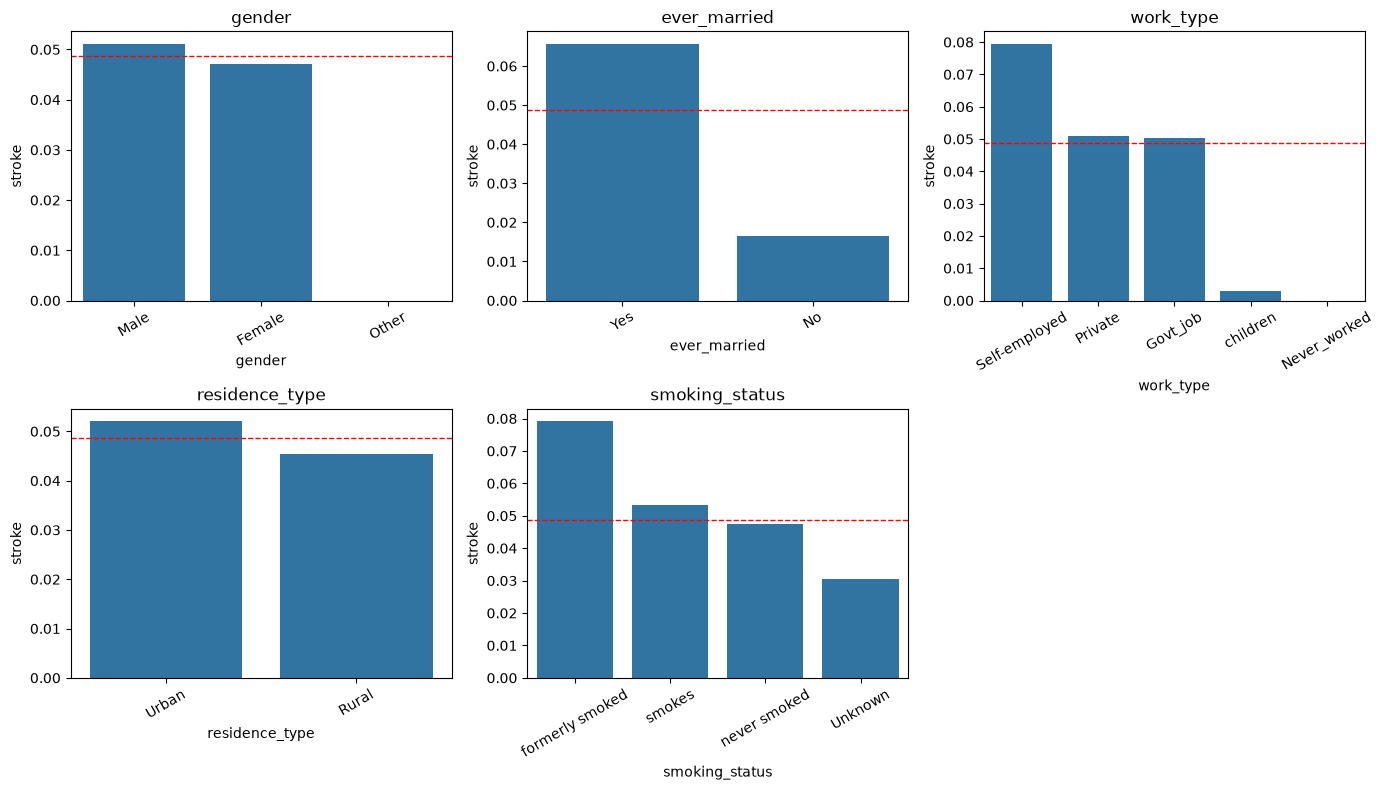

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, categorical_columns):
    order = stroke_data.groupby(col).stroke.mean().sort_values(ascending=False).index
    sns.barplot(data=stroke_data, x=col, y='stroke', order=order, ax=ax, errorbar=None)
    ax.axhline(global_stroke_rate, color='red', linestyle='--', linewidth=1)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

# Modeling

In [15]:
df_full_train, df_test = train_test_split(stroke_data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.stroke.values
y_val = df_val.stroke.values
y_test = df_test.stroke.values

In [16]:
def train(df_train, y_train, C=1.0):
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
            ('num', 'passthrough', numeric_columns),
        ]
    )

    X_train = preprocessor.fit_transform(df_train[feature_columns])

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return preprocessor, model


def predict(df, preprocessor, model):
    X = preprocessor.transform(df[feature_columns])
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred


preprocessor, model = train(df_train, y_train)
y_pred = predict(df_val, preprocessor, model)
roc_auc_score(y_val, y_pred)

0.842184317718941

,feature,coef,abs_coef
8,cat__work_type_children,0.585270,0.585270
17,num__heart_disease,0.454108,0.454108
7,cat__work_type_Self-employed,-0.435637,0.435637
16,num__hypertension,0.245083,0.245083
3,cat__ever_married_Yes,-0.217380,0.217380
2,cat__ever_married_No,0.193571,0.193571
13,cat__smoking_status_never smoked,-0.151090,0.151090
5,cat__work_type_Never_worked,-0.138797,0.138797
1,cat__gender_Male,-0.080348,0.080348
12,cat__smoking_status_formerly smoked,0.075764,0.075764


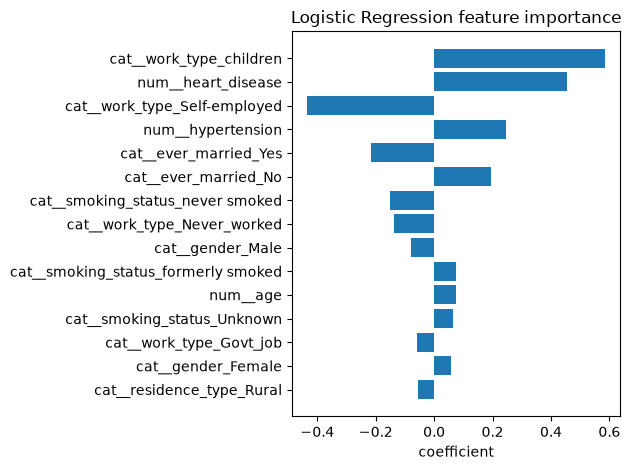

In [17]:
feature_names = preprocessor.get_feature_names_out()
lr_importance = pd.DataFrame({
    'feature': feature_names,
    'coef': model.coef_[0],
    'abs_coef': np.abs(model.coef_[0]),
}).sort_values('abs_coef', ascending=False)

display(lr_importance.head(15))

top = lr_importance.head(15).iloc[::-1]
plt.barh(top.feature, top.coef)
plt.xlabel('coefficient')
plt.title('Logistic Regression feature importance')
plt.tight_layout()
plt.show()

In [18]:
# Shared one-hot encoding for tree model experiments
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('num', 'passthrough', numeric_columns),
    ]
)

X_train = preprocessor.fit_transform(df_train[feature_columns])
X_val = preprocessor.transform(df_val[feature_columns])

In [19]:
# Random Forest: tune max_depth and n_estimators
rf_scores = []

for max_depth in [5, 10, 15, 20, None]:
    for n_estimators in range(10, 201, 10):
        rf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            class_weight='balanced',
            random_state=1,
            n_jobs=-1,
        )
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        rf_scores.append((max_depth, n_estimators, auc))

rf_scores_df = pd.DataFrame(rf_scores, columns=['max_depth', 'n_estimators', 'auc'])
rf_scores_df.sort_values('auc', ascending=False).head(10)

,max_depth,n_estimators,auc
5,5.0,60,0.838162
19,5.0,200,0.836380
18,5.0,190,0.836176
17,5.0,180,0.836049
15,5.0,160,0.835947
16,5.0,170,0.835871
4,5.0,50,0.835832
14,5.0,150,0.835438
6,5.0,70,0.834776
13,5.0,140,0.834267


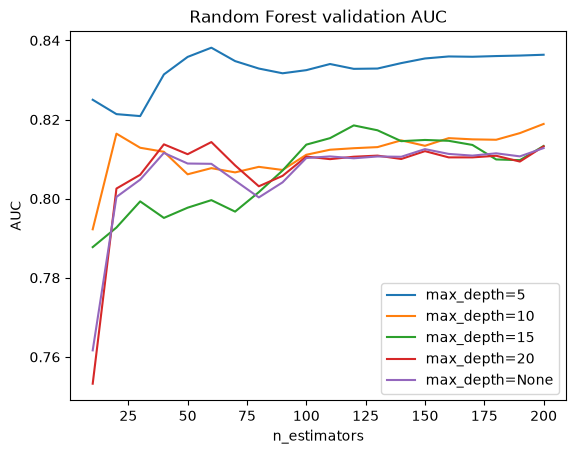

In [20]:
# Plot Random Forest AUC vs n_estimators for each max_depth
for max_depth in [5, 10, 15, 20, None]:
    subset = rf_scores_df[rf_scores_df.max_depth.isna() if max_depth is None else rf_scores_df.max_depth == max_depth]
    label = 'None' if max_depth is None else str(max_depth)
    plt.plot(subset.n_estimators, subset.auc, label=f'max_depth={label}')

plt.xlabel('n_estimators')
plt.ylabel('AUC')
plt.title('Random Forest validation AUC')
plt.legend()
plt.show()

,feature,importance
15,num__age,0.503206
19,num__bmi,0.119153
18,num__avg_glucose_level,0.106781
17,num__heart_disease,0.060132
3,cat__ever_married_Yes,0.051394
2,cat__ever_married_No,0.031206
16,num__hypertension,0.030262
8,cat__work_type_children,0.018693
7,cat__work_type_Self-employed,0.011419
1,cat__gender_Male,0.010344


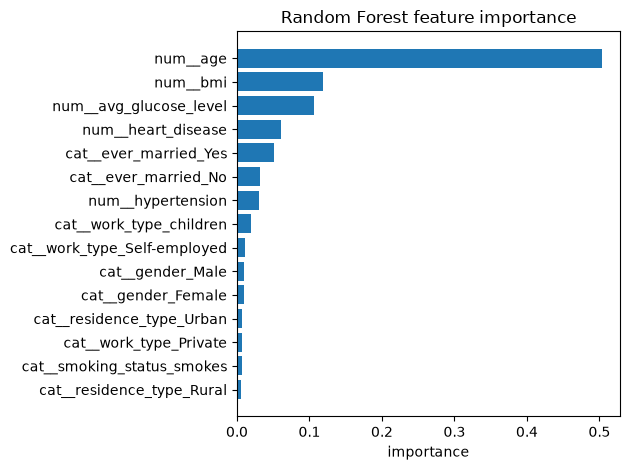

In [21]:
best_rf = rf_scores_df.sort_values('auc', ascending=False).iloc[0]
rf_best = RandomForestClassifier(
    n_estimators=int(best_rf.n_estimators),
    max_depth=None if pd.isna(best_rf.max_depth) else int(best_rf.max_depth),
    class_weight='balanced',
    random_state=1,
    n_jobs=-1,
)
rf_best.fit(X_train, y_train)

feature_names = preprocessor.get_feature_names_out()
rf_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_best.feature_importances_,
}).sort_values('importance', ascending=False)

display(rf_importance.head(15))

top = rf_importance.head(15).iloc[::-1]
plt.barh(top.feature, top.importance)
plt.xlabel('importance')
plt.title('Random Forest feature importance')
plt.tight_layout()
plt.show()

In [22]:
# Gradient Boosting: tune learning_rate, max_depth, and n_estimators
gbc_scores = []

for learning_rate in [0.01, 0.05, 0.1, 0.3]:
    for max_depth in [2, 3, 4, 5]:
        for n_estimators in range(10, 201, 10):
            gbc = GradientBoostingClassifier(
                learning_rate=learning_rate,
                max_depth=max_depth,
                n_estimators=n_estimators,
                random_state=1,
            )
            gbc.fit(X_train, y_train)

            y_pred = gbc.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            gbc_scores.append((learning_rate, max_depth, n_estimators, auc))

gbc_scores_df = pd.DataFrame(
    gbc_scores, columns=['learning_rate', 'max_depth', 'n_estimators', 'auc']
)
gbc_scores_df.sort_values('auc', ascending=False).head(10)

,learning_rate,max_depth,n_estimators,auc
141,0.05,5,20,0.854086
203,0.10,4,40,0.852953
68,0.01,5,90,0.852749
260,0.30,3,10,0.852584
65,0.01,5,60,0.852355
110,0.05,3,110,0.851948
109,0.05,3,100,0.851706
185,0.10,3,60,0.851591
183,0.10,3,40,0.851527
140,0.05,5,10,0.851311


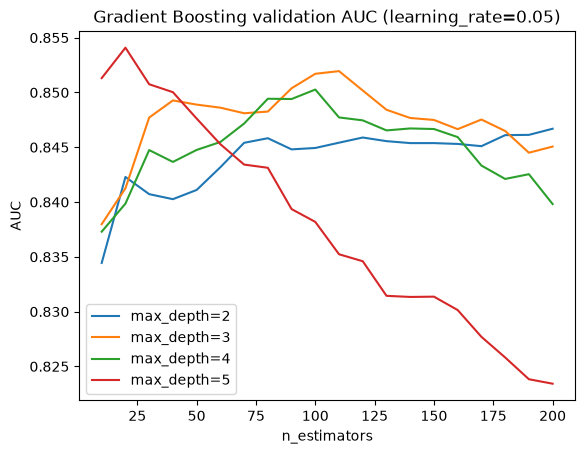

Best Random Forest:
 max_depth  n_estimators      auc
       5.0            60 0.838162

Best Gradient Boosting:
 learning_rate  max_depth  n_estimators      auc
          0.05          5            20 0.854086


In [23]:
# Plot Gradient Boosting AUC vs n_estimators for the best learning_rate / max_depth combos
best_lr = gbc_scores_df.sort_values('auc', ascending=False).iloc[0].learning_rate
best_depth = int(gbc_scores_df.sort_values('auc', ascending=False).iloc[0].max_depth)

for max_depth in [2, 3, 4, 5]:
    subset = gbc_scores_df[
        (gbc_scores_df.learning_rate == best_lr) & (gbc_scores_df.max_depth == max_depth)
    ]
    plt.plot(subset.n_estimators, subset.auc, label=f'max_depth={max_depth}')

plt.xlabel('n_estimators')
plt.ylabel('AUC')
plt.title(f'Gradient Boosting validation AUC (learning_rate={best_lr})')
plt.legend()
plt.show()

print('Best Random Forest:')
print(rf_scores_df.sort_values('auc', ascending=False).head(1).to_string(index=False))
print()
print('Best Gradient Boosting:')
print(gbc_scores_df.sort_values('auc', ascending=False).head(1).to_string(index=False))

,feature,importance
15,num__age,0.359145
18,num__avg_glucose_level,0.251977
19,num__bmi,0.227523
17,num__heart_disease,0.039275
14,cat__smoking_status_smokes,0.021196
7,cat__work_type_Self-employed,0.015963
2,cat__ever_married_No,0.014817
11,cat__smoking_status_Unknown,0.014209
16,num__hypertension,0.012248
0,cat__gender_Female,0.011579


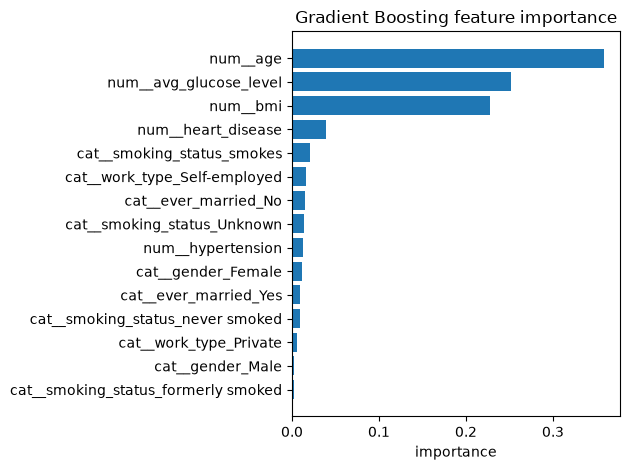

In [24]:
best_gbc = gbc_scores_df.sort_values('auc', ascending=False).iloc[0]
gbc_best = GradientBoostingClassifier(
    learning_rate=best_gbc.learning_rate,
    max_depth=int(best_gbc.max_depth),
    n_estimators=int(best_gbc.n_estimators),
    random_state=1,
)
gbc_best.fit(X_train, y_train)

feature_names = preprocessor.get_feature_names_out()
gbc_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': gbc_best.feature_importances_,
}).sort_values('importance', ascending=False)

display(gbc_importance.head(15))

top = gbc_importance.head(15).iloc[::-1]
plt.barh(top.feature, top.importance)
plt.xlabel('importance')
plt.title('Gradient Boosting feature importance')
plt.tight_layout()
plt.show()